### __BUSA8001 Group Assignment - Predicting Airbnb Listing Prices in Sydney__

--- 

**Due Date:** Friday, 3 June 2022 @ 11.59pm (Week 13)

**Overview:**   

- In the group assignment you will form a team of up to 3 students (minimum 2) and participate in a forecasting competition on Kaggle
- The goal is to predict listed property prices of Airbnb stays based on various Airbnb characteristics and regression models

- You will:  
    - Write a problem statement and perform Exploratory Data Analysis  
    - Clean up data, deal with categorical features and missing observations, and create new variables (feature engineering)  
    - Construct and tune forecasting models, produce forecasts and submit your predictions to Kaggle  
    - Each member of the team will record a video presentation of their work  
    - Marks will be awarded producing a prediction in the top 3 positions of their unit as well as for reaching the highest ranking on Kaggle amongst all teams.

**Instructions:** 

- Form a team of 3 students (minimum 2 students)  
- Each team member needs to join [https://www.kaggle.com](https://www.kaggle.com/)  
- Choose a team leader and form a team in the competition [https://www.kaggle.com/t/7455ad12c00e450394a6dd44fa676c67](https://www.kaggle.com/t/7455ad12c00e450394a6dd44fa676c67)
    - Team leader to click on `team` and join and invite other team members to join
    - There are two MQBS BUSA units competing in this competition
    - Your **team's name must start** with your unit code, for instance you could have a team called BUSA8001_masterful_geniuses 
- All team members should work on all the tasks listed below however   
    - **Choose a team member who will be responsible for one of each of the 3 tasks listed below**    

**Marks**: 

- Total Marks: 40
- Your mark will consist of:  
    - 50% x overall assignment mark + 45% x mark for the task that you are responsible for + 5% x mark received from your teammates for your effort in group work 
- 7 marks will be deducted from each Task for which there is no video presentation 

**Competition Marks:**
- 5 marks: Ranking in the top 3 places of your unit on Kaggle (make sure you name your team as instructed above)
- 2 marks: Reaching the first place in your unit  (make sure you name your team as instructed above)


**Submissions:**  

1. On Kaggle: submit your team's forecast in order to be ranked by Kaggle
    - Can do this as many times as necessary while building their model  
2. On iLearn **only team leader to submit** this Jupyter notebook re-named `Group_Assignment_MQ_ID.ipynb` where MQ_ID is team leader's MQ ID number 
    - The Jupyter notebook must contain team members names/ID numbers, and team name in the competition
    - Provide answers to the 3 Tasks below in the allocated cells including all codes/outputs/writeups 
    - One 15 minute video recording of your work 
        - Each team member to provide a 5 minute presentation of the Task that they led (it is best to jointly record your video using Zoom)
        - When recording your video make sure your face is visible, that you share your Jupyter Notebook and explain everything you've done in the submitted Jupyter notebook on screen
        - 7 marks will be deducted from each Task for which there is no video presentation or if you don't follow the above instructions
        
3. On iLearn each student needs to submit a file with their teammates' names, SID and a mark for their group effort (out of 100%)



---

**Fill out the following information**

For each team member provide name, Student ID number and which task is performed below

- Team Name on Kaggle: `BUSA8001_Outliers`
- Team Leader and Team Member 1: `Dac Anh Tai Pham - 46159223 - Task 1`
- Team Member 2: `Aarushi Chaudhary - 46113908 - Task 2`
- Team Member 3: `Kaveri Bhatia Chanana - 46282920 - Task 3`

---

## Task 1: Problem Description and Initial Data Analysis

1. Read the Competition Overview on Kaggle [https://www.kaggle.com/t/7455ad12c00e450394a6dd44fa676c67](https://www.kaggle.com/t/7455ad12c00e450394a6dd44fa676c67)
2. Referring to Competition Overview and the data provided on Kaggle write about a 500 words **Problem Description** focusing on key points that will need to be addressed as first steps in Tasks 2 and 3 below, using the following headings:
    - Forecasting Problem
    - Evaluation Criteria
    - Types of Variables/Features
    - Data summary and main data characteristics
    - Missing Values (only explain what you found at this stage)
    
Total Marks: 11


### Loading dataset and essential libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec 
import seaborn as sns
from scipy import stats
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from math import sqrt
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
import warnings
pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", None)

train_df=pd.read_csv('C:/E(Working)/Macquarie Topics/2022_Sem1/BUSA8001/Assessments/Group Assignment/data/train/train.csv')
test_df=pd.read_csv('C:/E(Working)/Macquarie Topics/2022_Sem1/BUSA8001/Assessments/Group Assignment/data/test/test.csv')

## Task 1 Problem Description
### i) Forecasting Problem
- The forecasting problem of this assignment is predicting Airbnb accommodation prices in Sydney based on the important features that are likely to impact the listing prices. We will use Regression Prediction Model for predicting continious target variable (price). The model is trained and tested based on the given training dataset before making predictions on the given test dataset.

### ii) Evaluation Criteria
- The predicted model of our team would be assessed by **Root Mean Square Error** (RMSE) which typically measures the standard deviation of the errors the model makes in its predictions. The RMSE is calculated as the square root of the expected mean difference between predicted price and available price. Our strategy is not only aim to pick the model with the lowest RMSE score, but also consider about the overfitting issue the model might have (not too much difference in train and test RMSE value).

$$RMSE=\sqrt{\frac{1}{m}\sum_{i=1}^m\left(y_{i} - \hat{y}_{i}\right)^2)}$$

- Where m is the number of observations, yi are observed prices, y^i are predicted prices.

### iii) Types of Variables/Features


In [242]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 61 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   ID                                            7000 non-null   int64  
 1   name                                          6999 non-null   object 
 2   description                                   6935 non-null   object 
 3   neighborhood_overview                         5183 non-null   object 
 4   host_name                                     7000 non-null   object 
 5   host_since                                    7000 non-null   object 
 6   host_location                                 6998 non-null   object 
 7   host_about                                    4542 non-null   object 
 8   host_response_time                            6355 non-null   object 
 9   host_response_rate                            6355 non-null   o

#### Comment:
Overall, there are three types of data in the dataset including integer, float, and object where integer and float datatype store numerical data, while object datatype stores list, date, text, and numerical.

There are some differences in datatype between the dataset and "Dataset Description" from Kaggle:
1. `instant_bookable`, `has_avaiability`, `host_identity_verified`, `host_has_profile_pic`, and `host_is_superhost` are should be stored as boolean like the "Dataset Description" state, whereas they are actually stored as object.
2. `host_since`, `first_review`, and `last_review` stored as object in the dataset but the "Dataset Description" states as "date" datatype.

Variables:
- `Price` (the 61st column) is our target variable; however, the datatype of `Price` is object which need to be altered to continous numerical value for the Regression prediction model. For example, the currency sign need to be removed from column `Price`.
- The other columns (60 columns) are potential independent variables that could have correlation relationships with our target variable.
- Some features are stored as wrong datatype (object) which is likely to affect our prediction model. For example, `instant_bookable`, `has_avaiability`, `host_identity_verified`, `host_has_profile_pic`, and `host_is_superhost` should be encoded and stored as integer. 
- Additionally, feature `bathrooms`, `host_acceptance_rate`, `host_response_rate` also need to be stored as a numeric value instead of object.
- Furthermore, `host_verifications` and `amenities` are object that store the lists of texts. The feature extraction could be applied to create potential independent variables for our model.

### iv) Data summary and main data characteristics

In [243]:
train_df.describe()

,ID,host_listings_count,latitude,longitude,accommodates,bedrooms,beds,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,availability_30,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,6340.000000,6760.000000,7000.000000,7000.000000,6955.000000,7000.000000,7000.000000,6.955000e+03,7000.000000,7.000000e+03,7000.000000,7000.000000,7000.000000,6953.000000,7000.000000,7000.000000,7000.000000,6886.000000,6790.000000,6792.000000,6791.000000,6792.000000,6790.000000,6789.000000,7000.000000,7000.000000,7000.000000,7000.000000,6886.000000
mean,3499.500000,13.315571,-33.848580,151.191887,3.757714,1.811830,2.243343,29.734571,773.551000,28.485981,30.343857,866.717143,3.088569e+06,29.434657,2.830644e+06,9.276286,24.313286,41.979429,167.068172,35.402429,6.957286,0.750714,4.631587,4.754588,4.658408,4.841571,4.841826,4.842272,4.643322,10.757143,8.696714,1.939714,0.044571,0.965577
std,2020.870275,32.683985,0.094001,0.106205,2.331416,1.073018,1.654179,42.407400,473.598247,41.940831,41.738467,434.408411,8.137667e+07,41.886924,7.498722e+07,10.233421,21.071782,31.883595,133.719203,58.590892,12.569829,1.578901,0.709730,0.447357,0.512783,0.380514,0.384644,0.317936,0.465086,24.279535,21.696069,11.120574,0.555544,1.240824
min,0.000000,0.000000,-34.090180,150.630490,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,1749.750000,1.000000,-33.894395,151.159120,2.000000,1.000000,1.000000,2.000000,200.000000,2.000000,2.000000,365.000000,9.990000e+02,2.000000,6.000000e+02,0.000000,2.000000,7.000000,40.000000,3.000000,0.000000,0.000000,4.590000,4.710000,4.560000,4.840000,4.840000,4.810000,4.540000,1.000000,1.000000,0.000000,0.000000,0.150000
50%,3499.500000,2.000000,-33.875625,151.212020,3.000000,1.000000,2.000000,3.000000,1125.000000,3.000000,5.000000,1125.000000,1.125000e+03,3.800000,1.125000e+03,5.000000,21.000000,43.000000,144.000000,12.000000,2.000000,0.000000,4.830000,4.890000,4.820000,4.960000,4.970000,4.940000,4.750000,2.000000,1.000000,0.000000,0.000000,0.520000
75%,5249.250000,6.000000,-33.801885,151.261272,5.000000,2.000000,3.000000,90.000000,1125.000000,90.000000,90.000000,1125.000000,1.125000e+03,90.000000,1.125000e+03,17.000000,43.000000,71.000000,310.000000,41.000000,9.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.920000,6.000000,4.000000,1.000000,0.000000,1.360000
max,6999.000000,354.000000,-33.392670,151.340410,16.000000,11.000000,22.000000,400.000000,1162.000000,400.000000,400.000000,1162.000000,2.147484e+09,400.000000,2.142625e+09,30.000000,60.000000,90.000000,365.000000,756.000000,280.000000,30.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,197.000000,197.000000,100.000000,17.000000,24.270000


In [244]:
train_df.nunique()

ID                                              7000
name                                            6908
description                                     6719
neighborhood_overview                           4465
host_name                                       2112
host_since                                      2405
host_location                                    631
host_about                                      2505
host_response_time                                 4
host_response_rate                                46
host_acceptance_rate                              89
host_is_superhost                                  2
host_neighbourhood                               170
host_listings_count                               60
host_verifications                               229
host_has_profile_pic                               2
host_identity_verified                             2
neighbourhood                                    479
neighbourhood_cleansed                        

#### Comment:
According to the numeric variables summary. There are some unsuals that need to have further investigation or action. Note that this summary cannot give us a full overview because some of the features have been stored as incorrect datatype as mentioned above.

- `host_listings_count` has min as 0 which does not make sense that some hosts has no listings (per Airbnb calculations), that is because of missing values.
- `maximum_maximum_nights`, and `maximum_nights_avg_ntm` have very strange count values which are 6.955000e+03, and 7.000000e+03 respectively. Especially `maximum_maximum_nights` should have min and max value as integer.

Other features appear in the summary as expected. Location indicator data such as `longtitude` and `latitude` has no missing value. `accommodates`, `bedrooms`, and	`beds` values make sense with min as 1 and all oberservation values of these columns are integer value. Furthremore, `accommodates` has no missing value. Lastly, the `review_scores_*` variables have min value as 0 and max value as 5 which are as our expectation because Airbnb uses 5-star rating.

There are some insights given by `nunique()` command.
- `neighbourhood_cleased` has 38 unique values while `neighbourhood` has 479 unique values indicating that `neighbourhood_cleansed` is more likely to be a good indicator in our prediction model as `neighbourhood` column sometimes include city, and state sometimes does not which generates more unique values.
- `bathrooms` has 30 unique while `bedrooms` only has 8 unique values, because `bathrooms` column contains some unique texts such as shared, private bathrooms that need to be cleaned in further step.


### v) Missing Values

We use the following command to find the total number of NA values for each column with descending order. 

In [245]:
train_df.isnull().sum(axis=0).sort_values(ascending= False)
#rain_df.isnull().sum(axis=0).sort_values(ascending= False)/len(train_df)*100

host_neighbourhood                              2912
host_about                                      2458
license                                         1868
neighborhood_overview                           1817
neighbourhood                                   1816
host_acceptance_rate                             745
bedrooms                                         660
host_response_time                               645
host_response_rate                               645
beds                                             240
review_scores_value                              211
review_scores_accuracy                           210
review_scores_location                           210
review_scores_checkin                            209
review_scores_cleanliness                        208
review_scores_communication                      208
room_type                                        134
review_scores_rating                             114
last_review                                   

Overall, the features that have the most missing values are:

| **Top 5 features have the most missing values** | **Percentage** |
| :- | -: |
| host_neighbourhood | 41.60|
| host_about | 35.11 |
| license | 26.68 |
| neighborhood_overview | 25.95 |
| neighbourhood | 25.94 |

There are some features have common number of missing values in relevant columns and these NA values might derive from the same observations.
- 45 NA values in `maximum_maximum_nights`, `minimum_minimum_nights`.
- 114 NA values in `review_scores_rating`, `last_review` ,`first_review`, and `reviews_per_month`.
- 208 values in `review_scores_value`, `review_scores_accuracy`, `review_scores_location`, `review_scores_checkin`, `review_scores_cleanliness`, `review_scores_communication`.
- 645 NA values in `host_response_time`, and `host_response_rate`.
- 1817 NA values in `neighbourhood_overview`, `neighbourhood`.

There are some tests run to assess if our intuition is correct.

In [246]:
#df_train[df_train['maximum_maximum_nights'].isnull()].isnull().sum(axis=0).sort_values(ascending=False)
#df_train[df_train['review_scores_rating'].isnull()].isnull().sum(axis=0).sort_values(ascending=False)
#df_train[df_train['review_scores_value'].isnull()].isnull().sum(axis=0).sort_values(ascending=False)
#df_train[df_train['host_response_time'].isnull()].isnull().sum(axis=0).sort_values(ascending=False)
train_df[train_df['neighborhood_overview'].isnull()].isnull().sum(axis=0).sort_values(ascending=False)

neighborhood_overview                           1817
neighbourhood                                   1816
host_about                                       911
host_neighbourhood                               852
license                                          678
host_acceptance_rate                             280
host_response_rate                               250
host_response_time                               250
bedrooms                                         190
beds                                             101
review_scores_accuracy                            95
review_scores_cleanliness                         95
review_scores_location                            95
review_scores_communication                       95
review_scores_value                               95
review_scores_checkin                             94
description                                       63
last_review                                       51
first_review                                  

Therefore, our intuition is correct as missing values derived from the same observations with the same number of missing values in relevant features (5 cases above, just testing one time for concise purpose).

The visualization below could show the observations have the same missing values among features.

<AxesSubplot:>

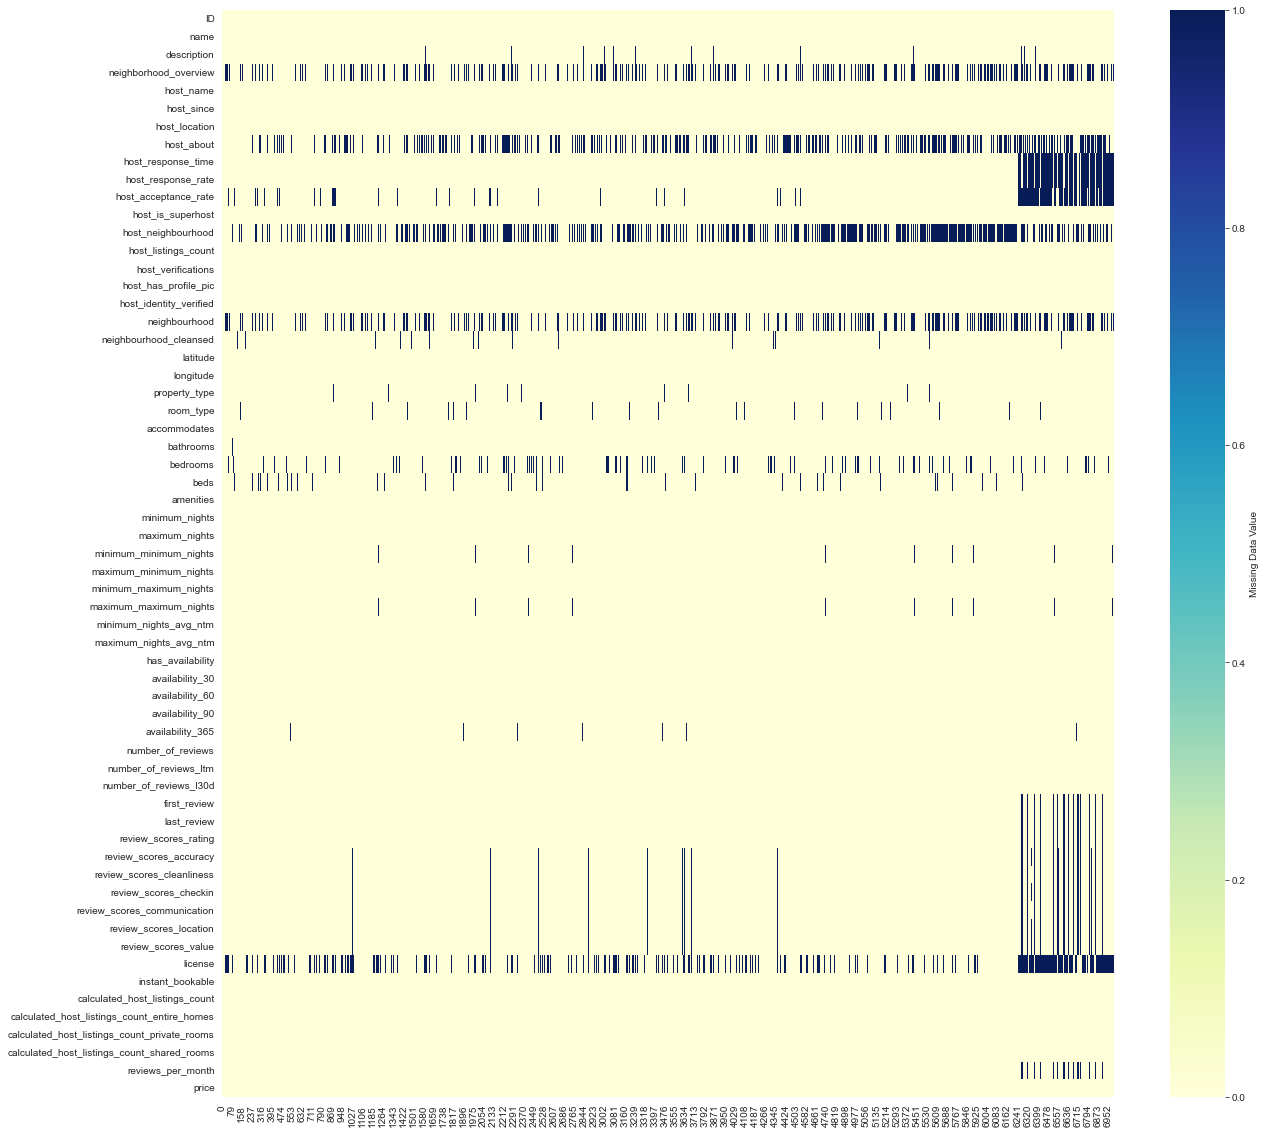

In [247]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20,20))
sns.heatmap(train_df.isna().transpose(),
            cmap="YlGnBu",
            cbar_kws={'label': 'Missing Data Value'})

#### Interpretation:
- The blue mark represents for missing value, while the white-yellow mark show the reverse.
- The horizontal direction of the blue mark indicates the intensity level of missing value in a feature, while the vertical direction of the blue mark portraits the observations that have missing values in several features.
- Based on the type of variable and its distribution, we could use mean, median or mode to fill the missing values.

#### Test dataset

In [248]:
test_df.isnull().sum(axis=0).sort_values(ascending= False)/len(test_df)*100

host_response_time                              84.466667
host_response_rate                              84.466667
license                                         79.766667
host_acceptance_rate                            76.166667
host_about                                      47.733333
host_neighbourhood                              42.100000
neighbourhood                                   41.333333
neighborhood_overview                           41.333333
review_scores_checkin                           21.433333
review_scores_value                             21.433333
review_scores_location                          21.400000
review_scores_accuracy                          21.366667
review_scores_cleanliness                       21.233333
review_scores_communication                     21.200000
first_review                                    15.533333
last_review                                     15.533333
reviews_per_month                               15.533333
review_scores_

<AxesSubplot:>

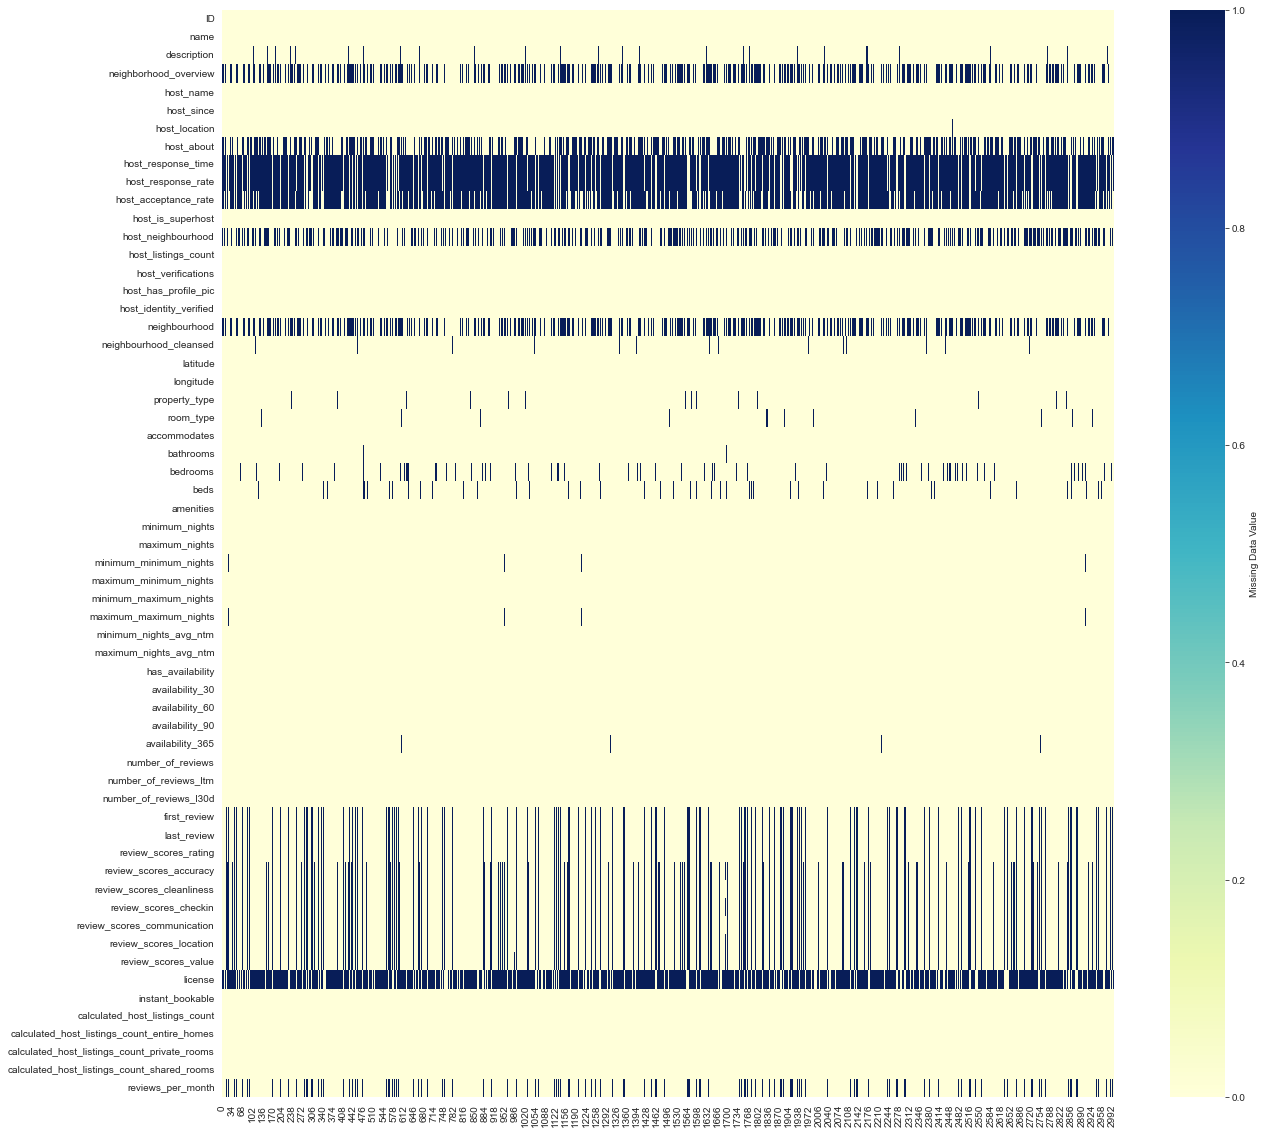

In [249]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20,20))
sns.heatmap(test_df.isna().transpose(),
            cmap="YlGnBu",
            cbar_kws={'label': 'Missing Data Value'})

#### Comment:

| **Top 5 features have the most missing values** | **Percentage** |
| :- | -: |
| host_response_time | 84.46|
| host_response_rate | 84.46 |
| license | 79.76 |
| host_acceptance_rate | 76.16 |
| host_about | 47.73 |

- Suprisingly, the missing values in the test dataset is significantly more than the train dataset.
- There are some features in the test dataset have reached optimal value in null value such as `host_response_time`, `host_response_rate`, `license`, `host_acceptance_rate`, etc. We might consider to drop these columns while cleaning the dataset instead of dropping the observations and filling the missing values for these values.
- Furthermore, the train and test datasets have significant number of missing values in some common features such as `host_neighbourhood`, `host_about`, `license`, `host_response_rate`, `host_response_time`, etc. We could consider to drop these columns before building a Regression Model.

---

## Task 2: Data Cleaning, Missing Observations and Feature Engineering
- In this task you will follow a set of instructions/questions listed below.
- Make sure you **explain** each step you do both in Markdown text and on your video.
- Do not just read out your commands without exaplaining what they do and why you used them 

Total Marks: 11

In [250]:
train_df.head(5)    

,ID,name,description,neighborhood_overview,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_neighbourhood,host_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,amenities,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price
0,0,Manly Harbour House,"Beautifully renovated, spacious and quiet, our...",Balgowlah Heights is one of the most prestigio...,Heidi,11/20/2009,"Sydney, New South Wales, Australia",I am a Canadian who has made Australia her hom...,within a few hours,100%,69%,t,Balgowlah,2,"['email', 'phone', 'reviews', 'jumio', 'offlin...",t,t,"Balgowlah, New South Wales, Australia",Manly,-33.80084,151.26378,Entire residential home,Entire home/apt,6,3 baths,3.0,3.0,"[""Hot water"", ""Coffee maker"", ""Heating"", ""Hair...",2,22,2.0,2,22,22.0,2.0,22.0,t,0,14,14,174.0,3,1,0,1/2/2016,6/1/2021,4.67,4.33,4.33,4.67,4.33,4.67,4.33,Exempt,f,2,2,0,0,0.04,$470.00
1,1,Unique Designer Rooftop Apartment in City Loca...,Penthouse living at it best ... You will be st...,The location is really central and there is nu...,Morag,12/3/2009,"Sydney, New South Wales, Australia",I am originally Scottish but I have made Sydne...,within an hour,100%,100%,f,Darlinghurst,3,"['email', 'phone', 'facebook', 'reviews', 'jum...",t,t,"Darlinghurst, New South Wales, Australia",Sydney,-33.87964,151.21680,Private room in rental unit,Private room,2,1 private bath,1.0,1.0,"[""Hot water"", ""Coffee maker"", ""Long term stays...",2,90,2.0,2,90,90.0,2.0,90.0,t,5,31,61,336.0,383,18,6,2/23/2012,12/3/2021,4.42,4.58,4.40,4.77,4.67,4.70,4.47,PID-STRA-24061-7,t,1,0,1,0,3.21,$82.00
2,2,"Studio Yindi @ Mosman, Sydney","An open plan apartment, which opens onto a spa...","Mosman is a smart, middle to upper class subur...",John,11/6/2010,"Sydney, New South Wales, Australia",Faber est suae quisquae fortunae\r\n\r\nWe bec...,within a few hours,100%,81%,t,Mosman,1,"['email', 'phone', 'facebook', 'reviews', 'jum...",t,t,"Mosman, New South Wales, Australia",Mosman,-33.81748,151.23484,Entire guest suite,Entire home/apt,4,1 bath,1.0,1.0,"[""Hot water"", ""Coffee maker"", ""Long term stays...",2,90,2.0,2,90,90.0,2.0,90.0,t,1,9,33,217.0,297,15,4,12/29/2010,11/30/2021,4.55,4.66,4.23,4.87,4.90,4.73,4.68,PID-STRA-6093,f,1,1,0,0,2.23,$150.00
3,3,"2br Eclectic Stylish Home, 2 mins to Bondi Beach","Two blocks to the beach, surf and coffee. Larg...",3 minutes to the beach and cafes. 5 minutes t...,Eilish,11/25/2010,"Bondi Beach, New South Wales, Australia","I'm a designer. I have lived in many cities, c...",within a day,100%,100%,t,Bondi Beach,1,"['email', 'phone', 'facebook', 'reviews', 'jum...",t,t,"Bondi Beach, New South Wales, Australia",Waverley,-33.88905,151.27653,Entire rental unit,Entire home/apt,4,1 bath,2.0,2.0,"[""Hot water"", ""Coffee maker"", ""Long term stays...",90,90,90.0,90,90,90.0,90.0,90.0,t,12,42,72,347.0,33,1,0,4/9/2011,4/7/2021,4.42,4.42,3.74,4.90,4.90,4.90,4.32,NaN,f,1,1,0,0,0.25,$245.00
4,4,A little bit of Sydney - Australia,"Hello Everyone,<br /><br />We have a quiet are...",NaN,Bryan,1/3/2011,"Sydney, New South Wales, Australia",We are living in Sydney. We like to see Wine r...,within an hour,100%,

**Task 2, Question 1**: Clean **all** numerical features and the target variable `price` so that they can be used in training algorithms. For instance, `host_response_rate` feature is in object format containing both numerical values and text. Extract numerical values (or equivalently eliminate the text) so that the numerical values can be used as a regular feature.  
(2 marks)

#### Data Cleaning and Manipulation

#### Understanding the distribution of Target Variable - Price

In [251]:
train_df['price'].describe()

count         7000
unique         812
top       $150.00 
freq           151
Name: price, dtype: object

In [252]:
train_df['price'] = train_df['price'].replace('[\$,]', '', regex=True).astype(float)

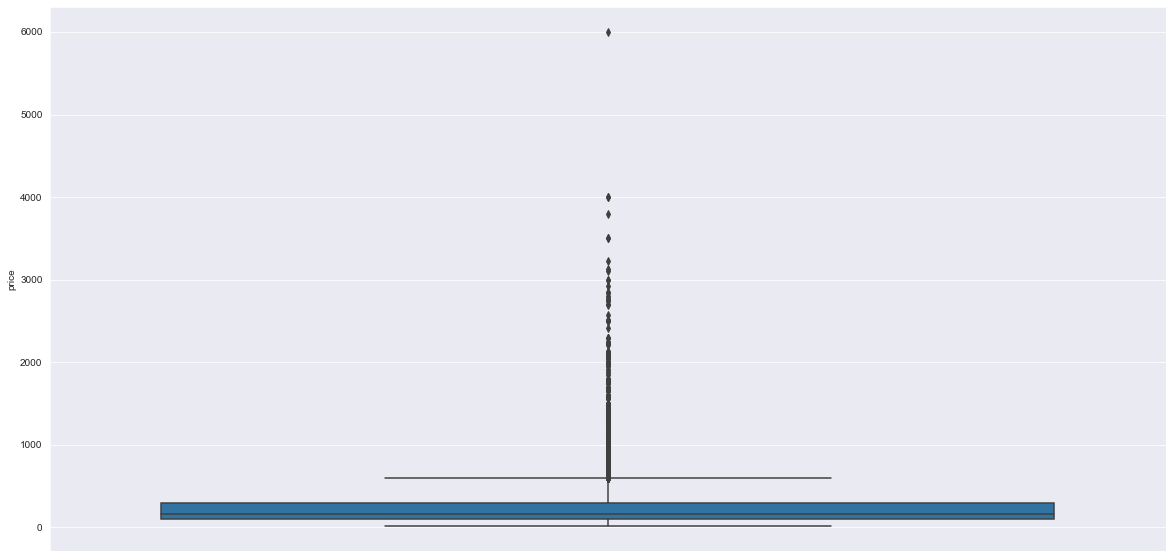

In [253]:
ax = sns.boxplot(y=train_df.price)
warnings.simplefilter(action='ignore')

The boxplot above, represents the distribution of target variable price.

In [254]:
train_df['price'].describe()

count    7000.000000
mean      271.167286
std       338.811123
min        17.000000
25%       100.000000
50%       168.000000
75%       299.000000
max      6000.000000
Name: price, dtype: float64

In [255]:
train_df['host_response_rate'].describe()

count     6355
unique      46
top       100%
freq      4571
Name: host_response_rate, dtype: object

In [256]:
train_df['host_response_rate'] = train_df['host_response_rate'].replace('[\%,]', '', regex=True).astype(float)
train_df['host_response_rate'].describe()

count    6355.000000
mean       92.501180
std        21.367348
min         0.000000
25%        99.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: host_response_rate, dtype: float64

In [257]:
train_df['host_acceptance_rate'].describe()

count     6255
unique      89
top       100%
freq      1618
Name: host_acceptance_rate, dtype: object

In [258]:
train_df['host_acceptance_rate'] = train_df['host_acceptance_rate'].replace('[\%,]', '', regex=True).astype(float)
train_df['host_acceptance_rate'].describe()

count    6255.000000
mean       81.643006
std        27.338910
min         0.000000
25%        75.000000
50%        95.000000
75%       100.000000
max       100.000000
Name: host_acceptance_rate, dtype: float64

After we extracted the numerical values from the numerical features and the target variable 'price', the train and test datasets were concatenated to quicken up the data cleaning and manipulation. This procedure was implemented so that we wouldn't have to clean the train and test datasets separately. We have, however, kept the IDs of the train and test data so that we can partition the dataset for regression analysis and prediction later.

In [259]:
df = pd.concat([train_df] + [test_df]).reset_index(drop=True)

In [260]:
df['price'].loc[1000:1020]

1000     153.0
1001      45.0
1002      86.0
1003    1286.0
1004    1121.0
1005     315.0
1006      29.0
1007     159.0
1008     160.0
1009      69.0
1010     750.0
1011     276.0
1012     249.0
1013    1200.0
1014     351.0
1015     720.0
1016     100.0
1017     117.0
1018     178.0
1019      50.0
1020     525.0
Name: price, dtype: float64

In [261]:
#Saving the ID of the test and train data 

train_id = train_df['ID']
test_id = test_df['ID']

**Task 2, Question 2** Create at least 4 new features from existing features which contain multiple items of information, e.g. creating `email`,  `phone`, `reviews`, `jumio`, etc. from feature `host_verifications`.  
(2 marks)

#### host_verifications

In [262]:
df['email'] =np.where(df['host_verifications'].str.contains('email', regex= True), 1, 0)
df['phone'] =np.where(df['host_verifications'].str.contains('phone', regex= True), 1, 0)
df['reviews'] =np.where(df['host_verifications'].str.contains('reviews', regex= True), 1, 0)
df['facebook'] =np.where(df['host_verifications'].str.contains('facebook', regex= True), 1, 0)
df['jumio'] =np.where(df['host_verifications'].str.contains('jumio', regex= True), 1, 0)

We have made 5 columns here for host_verifications namely email, phone, reviews, facebook and jumio. If the feature exist in the host_verfication column, it gives a value of 1 otherwise it gives a value of 0.

#### amenities

In [263]:
from ast import literal_eval

amenities=df.amenities.apply(literal_eval).explode().value_counts()
amenities.head(15)

Wifi                       9335
Long term stays allowed    9301
Essentials                 9293
Smoke alarm                9198
Kitchen                    9160
Washer                     8446
Hangers                    8390
Iron                       8168
Hair dryer                 7624
Shampoo                    7296
Hot water                  7105
TV                         6818
Heating                    6790
Dedicated workspace        6710
Dishes and silverware      6227
Name: amenities, dtype: int64

#### Comment:
- Wifi, long term stays allowed, essentials, smoke alarm, kitchen are the top 5 popular amenities in out airbnb listing dataset.
- So we may create 5 new columns for each of these amenities.

In [264]:
df['Wifi'] =np.where(df['amenities'].str.contains('Wifi', regex= True), 1, 0)
df['Long term stays allowed'] =np.where(df['amenities'].str.contains('Long term stays allowed', regex= True), 1, 0)
df['Essentials'] =np.where(df['amenities'].str.contains('Essentials', regex= True), 1, 0)
df['Smoke alarm'] =np.where(df['amenities'].str.contains('Smoke alarm', regex= True), 1, 0)
df['Kitchen'] =np.where(df['amenities'].str.contains('Kitchen', regex= True), 1, 0)

**Task 2, Question 3**: Impute missing values for all features in both training and test datasets.   
(2 marks)

#### Data Cleaning

In [265]:
df.head(1)

,ID,name,description,neighborhood_overview,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_neighbourhood,host_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,amenities,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price,email,phone,reviews,facebook,jumio,Wifi,Long term stays allowed,Essentials,Smoke alarm,Kitchen
0,0,Manly Harbour House,"Beautifully renovated, spacious and quiet, our...",Balgowlah Heights is one of the most prestigio...,Heidi,11/20/2009,"Sydney, New South Wales, Australia",I am a Canadian who has made Australia her hom...,within a few hours,100.0,69.0,t,Balgowlah,2.0,"['email', 'phone', 'reviews', 'jumio', 'offlin...",t,t,"Balgowlah, New South Wales, Australia",Manly,-33.80084,151.26378,Entire residential home,Entire home/apt,6,3 baths,3.0,3.0,"[""Hot water"", ""Coffee maker"", ""Heating"", ""Hair...",2,22,2.0,2.0,22.0,22.0,2.0,22.0,t,0,14,14,174.0,3,1,0,1/2/2016,6/1/2021,4.67,4.33,4.33,4.67,4.33,4.67,4.33,Exempt,f,2,2,0,0,0.04,470.0,1,1,1,0,1,1,0,1,1,1


First, we needed to count how many missing values there were in each column of the dataset. According to the results, there are 40,247 missing values in the combined data frame of test and train data. We'll address these missing numbers in the next section and decide whether to impute or erase them based on the impact on the Airbnb's listing prices. By tackling different areas of a property, we were able to organise the cleaning procedure. For example, we started with all the missing variables relating to the property's host and so on.

In [266]:
df.isna().sum().sort_values(ascending =False).head(40)

license                           4261
host_neighbourhood                4175
host_about                        3890
host_response_rate                3179
host_response_time                3179
neighborhood_overview             3057
neighbourhood                     3056
host_acceptance_rate              3030
price                             3000
review_scores_value                854
review_scores_checkin              852
review_scores_location             852
review_scores_accuracy             851
review_scores_cleanliness          845
review_scores_communication        844
bedrooms                           838
review_scores_rating               580
reviews_per_month                  580
first_review                       580
last_review                        580
beds                               369
room_type                          175
description                        154
neighbourhood_cleansed             150
property_type                      123
availability_365         

#### Features of Host

In [267]:
df['host_neighbourhood'] = df['host_neighbourhood'].fillna('NA')

df['host_about'] = df['host_about'].fillna('NA')

df['host_response_time'] = df['host_response_time'].fillna('NA')

df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].mode()[0])

df['host_acceptance_rate'] = df['host_acceptance_rate'].fillna(df['host_acceptance_rate'].mode()[0])

df['host_location'] = df['host_location'].fillna('NA')

#### Reviews

In [268]:
df['review_scores_value'] = df['review_scores_value'].fillna(df['review_scores_value'].mode()[0])

df['review_scores_checkin'] = df['review_scores_checkin'].fillna(df['review_scores_checkin'].mode()[0])

df['review_scores_location'] = df['review_scores_location'].fillna(df['review_scores_location'].mode()[0])

df['review_scores_accuracy'] = df['review_scores_accuracy'].fillna(df['review_scores_accuracy'].mode()[0])

df['review_scores_cleanliness'] = df['review_scores_cleanliness'].fillna(df['review_scores_cleanliness'].mode()[0])

df['review_scores_communication'] = df['review_scores_communication'].fillna(df['review_scores_communication'].mode()[0])

df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].mode()[0])

df['review_scores_rating'] = df['review_scores_rating'].fillna(df['review_scores_rating'].mode()[0])

#### Features of Property

In [269]:
df['bathrooms'] = df['bathrooms'].str.extract('(\d+)')

Here, the text value in the bathroom column was removed so that we are left with numerical data, which we can further use in our model.

In [270]:
df['license'] = df['license'].fillna('NA')

df['price'] = df['price'].fillna(df['price'].mode()[0])

df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].mode()[0])

df['beds'] = df['beds'].fillna(df['beds'].mode()[0])

df['room_type'] = df['room_type'].fillna('NA')

df['description'] = df['description'].fillna('NA')

df['property_type'] = df['property_type'].fillna('NA')

df['availability_365'] = df['availability_365'].fillna(df['availability_365'].mode()[0])

df['maximum_maximum_nights'] = df['maximum_maximum_nights'].fillna(df['maximum_maximum_nights'].mode()[0])

df['minimum_minimum_nights'] = df['minimum_minimum_nights'].fillna(df['minimum_minimum_nights'].mode()[0])

df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].mode()[0])

df['name'] = df['name'].fillna('NA')

#### Features of Neighbourhood

In [271]:
df['neighborhood_overview'] = df['neighborhood_overview'].fillna('NA')

df['neighbourhood'] = df['neighbourhood'].fillna('NA')

df['neighbourhood_cleansed'] = df['neighbourhood_cleansed'].fillna('NA')

As shown above, all the missing values were treated by replacing the missing text value to NA in the categorical colums. Similarly missing values in the numerical column were replaced by the mode of the column. 

**Task 2, Question 4**: Encode all categorical variables appropriately as discussed in class. 


Where a categorical feature contains more than 5 unique values, map the features into 5 most frequent values + 'other' and then encode appropriately. For instance, you could group then map `property_type` into 5 basic types + 'other': [entire rental unit, private room, entire room, entire towehouse, shared room, other] and then encode.  
(2 marks)

##### As we can see, **HostNeighbourhood** has majority of the data missing, this will be dropped from the dataset. Similarly, **HostAbout** and **HostLocation** will also be dropped.

In [272]:
df['host_response_time'].value_counts()

within an hour        4099
NA                    3179
within a few hours    1386
within a day           956
a few days or more     380
Name: host_response_time, dtype: int64

In [273]:
Mapping = dict()

Mapping['host_response_time'] = {'a few days or more': 4, 'within a day' : 3, 'within a few hours' : 2, 'within an hour' : 1, 'NA':0}
df['host_response_time'] = df.host_response_time.map(Mapping.get('host_response_time'))

In [274]:
df['room_type'].value_counts()

Entire home/apt    7063
Private room       2534
NA                  175
Hotel room          114
Shared room         114
Name: room_type, dtype: int64

In [275]:
Mapping['room_type'] = {'Shared room': 4, 'Hotel room' : 3, 'Private room' : 2, 'Entire home/apt' : 1, 'NA':0}
df['room_type'] = df.room_type.map(Mapping.get('room_type'))

In [276]:
df['property_type'].value_counts()

Entire rental unit                     4165
Entire residential home                1595
Private room in residential home       1039
Private room in rental unit             952
Entire guest suite                      305
Entire guesthouse                       245
Entire townhouse                        204
Entire condominium (condo)              150
Private room in townhouse               146
Room in boutique hotel                  138
NA                                      123
Entire serviced apartment               103
Entire cottage                           70
Room in hotel                            69
Entire loft                              56
Entire villa                             53
Private room in condominium (condo)      48
Shared room in rental unit               47
Private room in guest suite              47
Private room in villa                    43
Room in aparthotel                       39
Entire bungalow                          36
Private room in guesthouse      

In [277]:
df['property_type']=np.where(~df['property_type'].isin(['Entire rental unit','Entire residential home','Private room in residential home',
                                               'Private room in rental unit','Entire guest suite']), "Other", df['property_type'])

In [278]:
df['property_type'].value_counts()

Entire rental unit                  4165
Other                               1944
Entire residential home             1595
Private room in residential home    1039
Private room in rental unit          952
Entire guest suite                   305
Name: property_type, dtype: int64

In [279]:
Mapping['property_type'] = {'Entire rental unit': 5, 'Entire residential home' : 4, 'Private room in residential home' : 3, 'Private room in rental unit' : 2, 'Entire guest suite': 1, 'Other' : 0}
df['property_type'] = df.property_type.map(Mapping.get('property_type'))

In [280]:
df['property_type'].value_counts()

5    4165
0    1944
4    1595
3    1039
2     952
1     305
Name: property_type, dtype: int64

**Task 2, Question 5**: Perform any other actions you think need to be done on the data before constructing predictive models, and clearly explain what you have done.   
(1 marks)

In [281]:
useless = ['neighbourhood', 'neighborhood_overview', 'name', 'license']
df.drop(useless, axis=1, inplace=True)

In [282]:
df.shape

(10000, 67)

As we can see from the above, the features neighbourhood, neighbourhood, and license has the maximum number of missing values. In addition these are categorical values which cannot be used in our model further so we have decided to drop them from the datset. 
We can see that the name features have a large number of unique values. It would require some natural language processing to properly wrangle these into useful features. We believe we have enough location information with neighbourhood_cleansed so we'll name. 

We strongly believe that the number of amenities for each airbnb accommodation would have a significant impact on the airbnb listing price. As amenities is the lists of texts seperated by ',' so that we would return the count number of ',' and plus 1 to have the total counts of every texts in the list.

In [283]:
namenities = df['amenities'].str.count(',').clip(lower=1)
df['number_of_amenities'] = namenities+1

In [284]:
df['number_of_amenities'].head(5)

0    29
1    40
2    31
3    32
4    54
Name: number_of_amenities, dtype: int64

In [285]:
df.columns

Index(['ID', 'description', 'host_name', 'host_since', 'host_location',
       'host_about', 'host_response_time', 'host_response_rate',
       'host_acceptance_rate', 'host_is_superhost', 'host_neighbourhood',
       'host_listings_count', 'host_verifications', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bedrooms', 'beds', 'amenities', 'minimum_nights', 'maximum_nights',
       'minimum_minimum_nights', 'maximum_minimum_nights',
       'minimum_maximum_nights', 'maximum_maximum_nights',
       'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'has_availability',
       'availability_30', 'availability_60', 'availability_90',
       'availability_365', 'number_of_reviews', 'number_of_reviews_ltm',
       'number_of_reviews_l30d', 'first_review', 'last_review',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanlines

In [286]:
Mapping['host_is_superhost'] = {'t': 1, 'f': 0}
df['host_is_superhost'] = df.host_is_superhost.map(Mapping.get('host_is_superhost'))

Mapping['host_identity_verified'] = {'t': 1, 'f': 0}
df['host_identity_verified'] = df.host_identity_verified.map(Mapping.get('host_identity_verified'))

**Task 2, Question 6**: Perform exploratory data analysis to measure the relationship between the features and the target and write up your findings. 
(2 marks)

In [287]:
import numpy as np
from sklearn import preprocessing

# Function to label encode categorical variables.
# Input: array (array of values)
# Output: array (array of encoded values)
def encode_categorical(array):
    if not array.dtype == np.dtype('float64'):
        return preprocessing.LabelEncoder().fit_transform(array) 
    else:
        return array
    

In [288]:
temp_data = df.copy()
corr_matrix = temp_data.corr()
corr_matrix

,ID,host_response_time,host_is_superhost,host_listings_count,host_identity_verified,latitude,longitude,property_type,room_type,accommodates,bedrooms,beds,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,availability_30,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price,email,phone,reviews,facebook,jumio,Wifi,Long term stays allowed,Essentials,Smoke alarm,Kitchen,number_of_amenities
ID,1.000000,-0.548364,-0.288123,-0.002528,-0.171101,-0.074269,-0.019663,-0.010363,0.130006,-0.105065,-0.057064,-0.090537,0.394932,0.183583,0.394456,0.394634,0.167205,-0.009443,0.396661,-0.009914,-0.141060,-0.213615,-0.260565,-0.344812,-0.366403,-0.215098,-0.165153,-0.112363,-0.024557,-0.051293,-0.024941,-0.034365,-0.021893,0.018967,-0.027407,-0.040062,0.024513,0.038144,-0.227370,-0.194483,-0.085756,-0.044512,-0.185482,0.060638,-0.110221,-0.045666,0.136720,-0.005540,-0.085240,0.076692,-0.295159
host_response_time,-0.548364,1.000000,0.031430,0.035565,0.053827,0.118791,0.032352,0.028854,-0.107158,0.151982,0.156499,0.131294,-0.198378,-0.151478,-0.199152,-0.199663,-0.174977,-0.012256,-0.199234,-0.011823,0.254537,0.294527,0.319550,0.312993,0.009436,0.003521,-0.004026,0.102143,0.042841,0.082377,0.015489,0.023837,0.045440,0.034650,0.060028,0.074565,-0.020462,-0.035904,-0.004603,0.203386,-0.004979,0.024655,-0.001821,-0.069851,0.039564,0.002147,-0.086839,-0.003610,0.018069,-0.003191,0.151624
host_is_superhost,-0.288123,0.031430,1.000000,-0.125394,0.148367,0.063923,-0.031904,-0.048392,-0.075105,-0.025981,-0.054809,-0.032903,-0.276431,-0.158887,-0.269365,-0.274404,-0.057377,0.010049,-0.273692,0.012495,-0.089005,-0.031157,0.012828,0.063947,0.364160,0.310303,0.262749,0.168459,0.151009,0.183862,0.125575,0.136464,0.089935,0.150651,-0.151482,-0.137033,-0.058965,-0.036163,0.344205,0.007615,0.051033,0.027200,0.036966,-0.019453,0.072122,0.036030,-0.153127,0.016821,0.093435,-0.075878,0.270339
host_listings_count,-0.002528,0.035565,-0.125394,1.000000,-0.086046,-0.021448,0.041205,0.125057,-0.089924,0.057374,0.049458,0.024342,-0.100055,0.046439,-0.108479,-0.092505,0.029573,-0.006360,-0.101469,-0.006413,0.082705,0.085856,0.087559,0.173060,-0.083835,-0.016902,-0.028061,-0.009655,-0.069889,-0.051435,-0.084034,-0.103055,-0.004127,-0.093626,0.918339,0.888274,0.248690,-0.009754,-0.038352,0.070438,0.042370,0.015822,-0.038021,-0.118237,0.025348,0.026481,0.063146,0.030693,-0.002103,0.053564,0.053878
host_identity_verified,-0.171101,0.053827,0.148367,-0.086046,1.000000,0.024749,0.041231,0.023420,-0.089440,0.077915,0.047396,0.062602,-0.203554,-0.071319,-0.209065,-0.203619,-0.048040,0.013160,-0.206405,0.013132,-0.058111,-0.022051,0.001089,0.037579,0.144290,0.130273,0.107478,0.133609,0.078636,0.075151,0.063710,0.074614,0.058951,0.057342,-0.071063,-0.093544,0.038382,0.004080,0.160055,0.073422,0.130008,0.052114,0.108478,0.000054,0.433157,0.048331,-0.019449,0.034061,0.060176,-0.026229,0.151768
latitude,-0.074269,0.118791,0.063923,-0.021448,0.024749,1.000000,0.143869,-0.016947,-0.118526,0.188950,0.201590,0.180853,-0.129922,-0.115964,-0.121678,-0.126133,-0.126663,-0.012878,-0.125394,-0.012727,-0.019474,0.000413,0.023327,0.068151,-0.003574,0.030921,0.059786,0.060744,0.056057,0.071542,0.050618,0.045184,0.047822,0.025505,-0.027672,-0.005238,-0.055772,-0.023904,0.024494,0.245685,0.015105,0.004830,-0.010959,-0.025825,0.007465,-0.030325,-0.136241,-0.008883,0.012830,-0.009591,0.118767
longitude,-0.019663,0.032352,-0.031904,0.041205,0.041231,0.143869,1.000000,0.173878,-0.145828

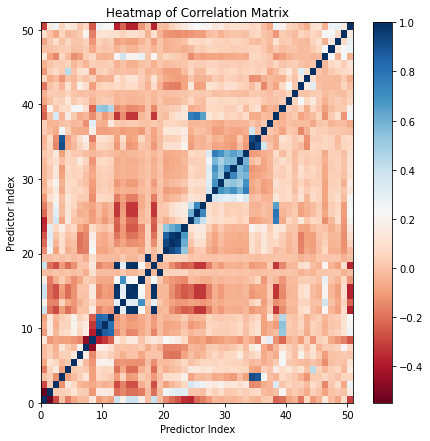

In [53]:
plt.figure(figsize=(7, 7))
plt.pcolor(corr_matrix, cmap='RdBu')
plt.xlabel('Predictor Index')
plt.ylabel('Predictor Index')
plt.title('Heatmap of Correlation Matrix')
plt.colorbar()

plt.show()

In [289]:
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape),k=1).astype(np.bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.90)]
print(); print(to_drop)


['minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_60', 'availability_90', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes']


This reveals that the above mentioned features are highly uncorrelated. So, we have decided to drop these features.

In [290]:
df = df.drop(['minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_60', 'availability_90', 'calculated_host_listings_count',
             'calculated_host_listings_count_entire_homes'], axis=1)

In [291]:
df.columns

Index(['ID', 'description', 'host_name', 'host_since', 'host_location',
       'host_about', 'host_response_time', 'host_response_rate',
       'host_acceptance_rate', 'host_is_superhost', 'host_neighbourhood',
       'host_listings_count', 'host_verifications', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bedrooms', 'beds', 'amenities', 'minimum_nights', 'maximum_nights',
       'minimum_maximum_nights', 'maximum_maximum_nights', 'has_availability',
       'availability_30', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review',
       'last_review', 'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'instant_bookable',
       'calculated_h

#### neighbourhood_cleansed

- We have decided to explore a little bit about neighbourhood_cleansed feature as we believe they are an important feature for our model.

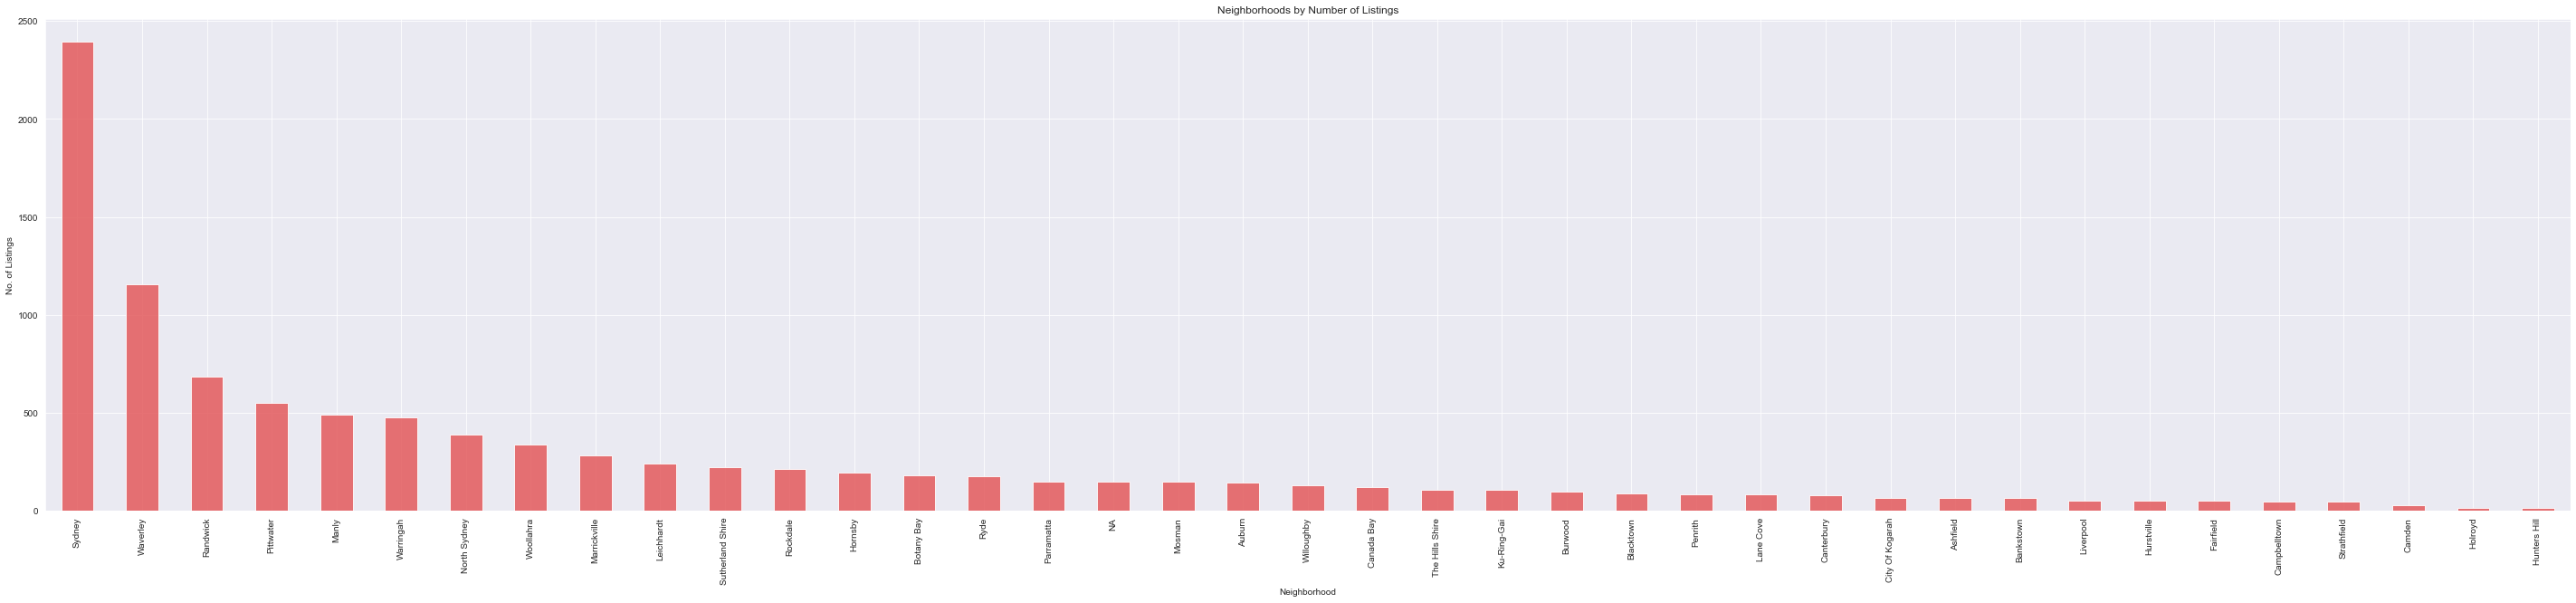

Number of Neighborhoods: 39


In [292]:
# Get number of listings in neighborhoods
count_per_neighborhood = df['neighbourhood_cleansed'].value_counts()

# Plot number of listings in each neighborhood
ax = count_per_neighborhood.plot(kind='bar', figsize = (50,10), color = '#E35A5C', alpha = 0.85)
ax.set_title("Neighborhoods by Number of Listings")
ax.set_xlabel("Neighborhood")
ax.set_ylabel("No. of Listings")
plt.show()

print("Number of Neighborhoods:", len(count_per_neighborhood))

The distribution is fine and there are only 39 neighborhoods. 

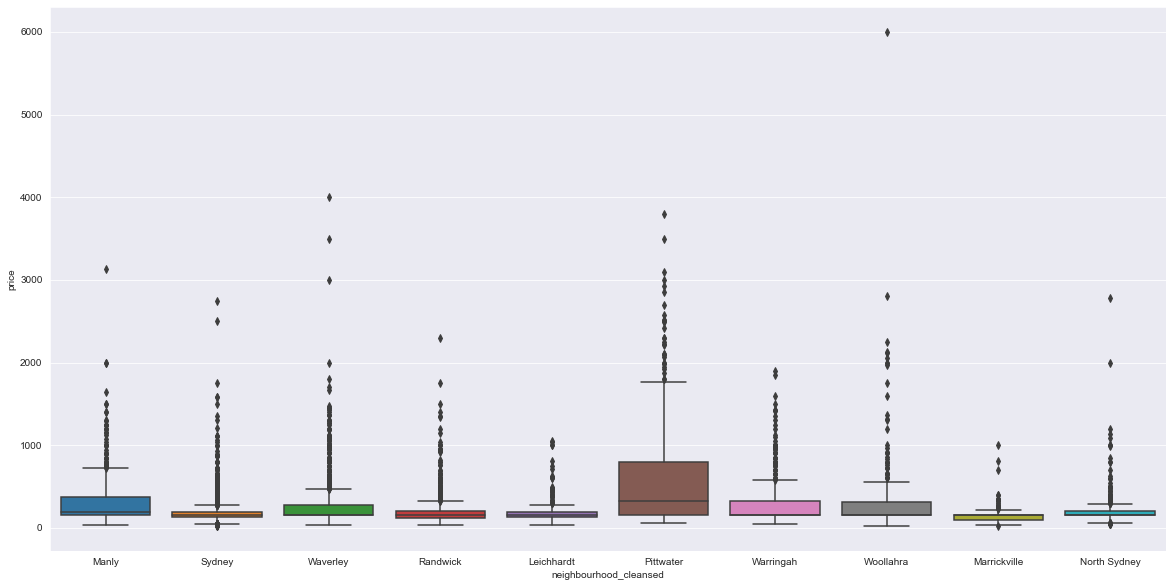

In [293]:
popularlocation = df['neighbourhood_cleansed'].value_counts()[:10].index.tolist();
#Getting the rows only which has selected 10 companies
dfd = df[pd.DataFrame(df.neighbourhood_cleansed.tolist()).isin(popularlocation).any(1).values];
#Plotting the Graph with sliced data
plt.rcParams['figure.figsize']=(20,10)
ax = sns.boxplot(x="neighbourhood_cleansed", y="price", data=dfd)

#### Comment:
- The box plot indicates that Airbnb listing prices in **Pittwater** have the wides range in price followed by **Manly**. Whereas **Woollahra** surburb has reached the peak which is approximately $6,000 a day.

--- 
## Task 3: Fit and tune a forecasting model/Submit predictions/Report score and ranking

Make sure you **clearly explain each step** you do, both in text and on the recoded video.

1. Build a machine learning (ML) regression model taking into account the outcomes of Tasks 1 & 2
2. Fit the model and tune hyperparameters via cross-validation: make sure you comment and explain each step clearly
3. Create predictions using the test dataset and submit your predictions on Kaggle's competition page
4. Provide Kaggle ranking and **score** (screenshot your best submission) and comment
5. Make sure your Python code works, so that a marker that can replicate your all of your results and obtain the same MSE from Kaggle

- Hint: to perform well you will need to iterate Task 3, building and tuning various models in order to find the best one.

Total Marks: 11

### Scopes
This part will reduce the number of features based on the correlation relationship (task 2) and the data characteristics (task 1). We also split the training dataset into 2 parts to test the overfitting issue of the models. We have implementing feature importance and training prediction model then evaluating based on RMSE. We not only aim to pick the model that has the least RMSE but also the model that has a fair RMSE value between the train and test dataset.

### 1. Dropping more insignificant features

In [294]:
df = df.drop(['description', 'host_name', 'host_since', 'host_location','host_about','host_response_rate',
             'host_acceptance_rate','host_neighbourhood','host_listings_count','host_verifications','latitude',
             'longitude','has_availability','instant_bookable','amenities','first_review','last_review','host_has_profile_pic','maximum_maximum_nights'], axis=1)

In [295]:
df.columns

Index(['ID', 'host_response_time', 'host_is_superhost',
       'host_identity_verified', 'neighbourhood_cleansed', 'property_type',
       'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
       'minimum_nights', 'maximum_nights', 'minimum_maximum_nights',
       'availability_30', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'calculated_host_listings_count_private_rooms',
       'calculated_host_listings_count_shared_rooms', 'reviews_per_month',
       'price', 'email', 'phone', 'reviews', 'facebook', 'jumio', 'Wifi',
       'Long term stays allowed', 'Essentials', 'Smoke alarm', 'Kitchen',
       'number_of_amenities'],
      dtype='object')

### 2. Building the Machine Learning model
#### 2.1 Using get_dummies to perform feature encoding for `neighbourhood_cleansed`.

In [296]:
df = pd.get_dummies(df, columns=['neighbourhood_cleansed'])

In [323]:
df.shape

(10000, 79)

#### 2.2 Split the dataset for training models and predicting.

In [325]:
train_df=df.loc[0:7000,]
test_df=df.loc[7000:]
test_df=test_df.drop('price',axis=1)

In [326]:
train_df.head()

,ID,host_response_time,host_is_superhost,host_identity_verified,property_type,room_type,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,minimum_maximum_nights,availability_30,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price,email,phone,reviews,facebook,jumio,Wifi,Long term stays allowed,Essentials,Smoke alarm,Kitchen,number_of_amenities,neighbourhood_cleansed_Ashfield,neighbourhood_cleansed_Auburn,neighbourhood_cleansed_Bankstown,neighbourhood_cleansed_Blacktown,neighbourhood_cleansed_Botany Bay,neighbourhood_cleansed_Burwood,neighbourhood_cleansed_Camden,neighbourhood_cleansed_Campbelltown,neighbourhood_cleansed_Canada Bay,neighbourhood_cleansed_Canterbury,neighbourhood_cleansed_City Of Kogarah,neighbourhood_cleansed_Fairfield,neighbourhood_cleansed_Holroyd,neighbourhood_cleansed_Hornsby,neighbourhood_cleansed_Hunters Hill,neighbourhood_cleansed_Hurstville,neighbourhood_cleansed_Ku-Ring-Gai,neighbourhood_cleansed_Lane Cove,neighbourhood_cleansed_Leichhardt,neighbourhood_cleansed_Liverpool,neighbourhood_cleansed_Manly,neighbourhood_cleansed_Marrickville,neighbourhood_cleansed_Mosman,neighbourhood_cleansed_NA,neighbourhood_cleansed_North Sydney,neighbourhood_cleansed_Parramatta,neighbourhood_cleansed_Penrith,neighbourhood_cleansed_Pittwater,neighbourhood_cleansed_Randwick,neighbourhood_cleansed_Rockdale,neighbourhood_cleansed_Ryde,neighbourhood_cleansed_Strathfield,neighbourhood_cleansed_Sutherland Shire,neighbourhood_cleansed_Sydney,neighbourhood_cleansed_The Hills Shire,neighbourhood_cleansed_Warringah,neighbourhood_cleansed_Waverley,neighbourhood_cleansed_Willoughby,neighbourhood_cleansed_Woollahra
0,0,2,1,1,4,1,6,3,3.0,3.0,2,22,22.0,0,174.0,3,1,0,4.67,4.33,4.33,4.67,4.33,4.67,4.33,0,0,0.04,470.0,1,1,1,0,1,1,0,1,1,1,29,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,1,0,1,2,2,2,1,1.0,1.0,2,90,90.0,5,336.0,383,18,6,4.42,4.58,4.40,4.77,4.67,4.70,4.47,1,0,3.21,82.0,1,1,1,1,1,1,1,1,1,1,40,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,2,2,1,1,1,1,4,1,1.0,1.0,2,90,90.0,1,217.0,297,15,4,4.55,4.66,4.23,4.87,4.90,4.73,4.68,0,0,2.23,150.0,1,1,1,1,1,1,1,1,1,1,31,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,3,3,1,1,5,1,4,1,2.0,2.0,90,90,90.0,12,347.0,33,1,0,4.42,4.42,3.74,4.90,4.90,4.90,4.32,0,0,0.25,245.0,1,1,1,1,1,1,1,1,1,1,32,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,4,1,1,1,3,2,4,2,2.0,3.0,1,30,30.0,26,358.0,61,15,0,4.95,4.93,4.98,4.98,5.00,4.79,4.93,1,0,0.48,89.0,1,1,1,0,1,1,1,1,1,1,54,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


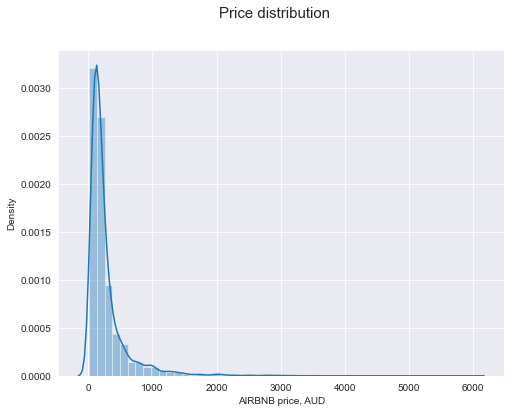

In [327]:
sns.set_style('darkgrid')
fig,ax = plt.subplots(1,1,figsize=(8,6))
sns.distplot(train_df['price'], ax=ax)
ax.set_xlabel('AIRBNB price, AUD')
plt.suptitle('Price distribution', size=15)
plt.show()

Comment: The most of the Airbnb listing prices are approximately between 100 and 500 Australian Dollars. 

#### 2.3 Dropping unumerical datatype features.

In [302]:
train_df.dtypes.value_counts()

uint8      39
int64      16
float64    13
int32      10
object      1
dtype: int64

We would just only keep numerical feature in our training model as the ML cannot take object datatype.

In [303]:
numerics_type = [ 'int16', 'int32', 'int64', 'float16', 'float32', 'float64']
numeric_features = train_df.select_dtypes(include=numerics_type)

In [304]:
for feature in numeric_features.columns:
    if feature not in train_df.columns:
        numeric_features.drop(feature, axis=1, inplace=True)

In [305]:
to_transform = [index for index in numeric_features.columns 
                if np.abs(train_df[index].skew()) > 0.9]
to_transform

['host_response_time',
 'host_identity_verified',
 'room_type',
 'accommodates',
 'bedrooms',
 'beds',
 'minimum_nights',
 'minimum_maximum_nights',
 'number_of_reviews',
 'number_of_reviews_ltm',
 'number_of_reviews_l30d',
 'review_scores_rating',
 'review_scores_accuracy',
 'review_scores_cleanliness',
 'review_scores_checkin',
 'review_scores_communication',
 'review_scores_location',
 'review_scores_value',
 'calculated_host_listings_count_private_rooms',
 'calculated_host_listings_count_shared_rooms',
 'reviews_per_month',
 'price',
 'email',
 'phone',
 'facebook',
 'Wifi',
 'Long term stays allowed',
 'Essentials',
 'Smoke alarm',
 'Kitchen']

In [306]:
for feature in to_transform:
    if train_df[feature].all():
        train_df[feature] = np.log(train_df[feature])
    if (feature in test_df.columns) and (test_df[feature].all()):
        test_df[feature] = np.log(test_df[feature])
        

#### 2.4 We then split the data for x and y which accounts for independent variables and target variable, respectively.

In [307]:
x2 = train_df.drop(["price","ID"],axis=1)
x2_test=test_df.drop(['ID'],axis =1)
y2 = train_df['price']

We split the train dataset by `train_test_split` command for evaluation purpose with 20% test size.

In [308]:
X_train, X_test, y_train, y_test = train_test_split(x2, y2, test_size=0.2, random_state=0)

### 3. Fitting several models and comparison

#### 3.1 Random Forest Important Features

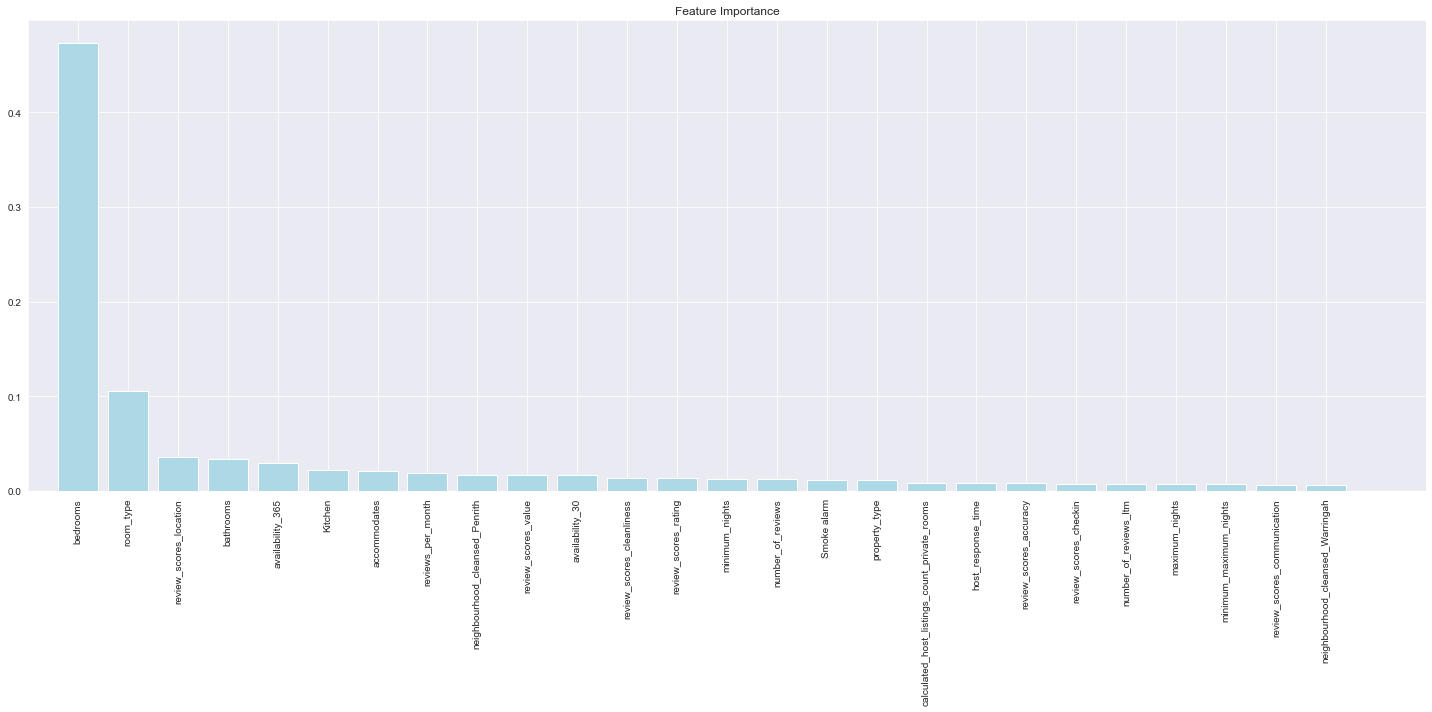

In [309]:
forest = RandomForestRegressor(n_estimators=100, criterion="mse",n_jobs=-1,random_state=1)

forest.fit(X_train,y_train)

feat_labels = train_df.columns[1:]
importances = forest.feature_importances_

# print(importances)  # prints importances of each feature
# print(np.argsort(importances)) # sort the index of importances from smallest to largest
# print(np.argsort(importances)[::-1]) # reverses the index to get largest to smallest


indices = np.argsort(importances)[::-1][:26]

# print(X_train.shape)
# for f in range(X_train.shape[1]):
# #     print(f, indices[f])   # pick up positions from indices 
#     print(f'{f+1:2})  {feat_labels[indices[f]]:40} {importances[indices[f]]:10}')
    
plt.title('Feature Importance')
plt.bar(range(26),importances[indices], color='lightblue', align='center')
plt.xticks(range(26), feat_labels[indices], rotation=90)
plt.xlim([-1, 27])
plt.tight_layout()
plt.show()

#### Visualization comment:
- The feature importance package from RandomForest Regression indicates that `bedrooms`, `room_type`, and `review_scores_location` are the top 3 significant independent variable for its model.

#### 3.2 Linear Regression

In [310]:
slr = LinearRegression()

slr.fit(X_train, y_train)

y_train_pred = slr.predict(X_train)
y_test_pred = slr.predict(X_test)


print(f'RMSE train: {sqrt(mean_squared_error(y_train, y_train_pred)):.4f}, test: {sqrt(mean_squared_error(y_test, y_test_pred)):.4f}')
print(f'R^2 train: {r2_score(y_train, y_train_pred):.4f}, test: {r2_score(y_test, y_test_pred):.4f}')

RMSE train: 0.4421, test: 0.4406
R^2 train: 0.7400, test: 0.7327


#### 3.3 Lasso Regression

In [311]:
lasso = Lasso()

param_range = [0.0001, 0.001, 0.01, 0.1, 1.0]  # range of values for alpha 

param_grid = [{'alpha': param_range}]  # range of values for all parameters

gs_lasso = GridSearchCV(estimator=lasso,      # initialise gs object
                  param_grid=param_grid, 
                  scoring='neg_root_mean_squared_error', 
                  refit=True,              # this will refit the best estimator to the whole dataset automatically
                  cv=10,
                  n_jobs=-1)


gs_lasso = gs_lasso.fit(X_train, y_train)            # fit gs
print(gs_lasso.best_score_)
print(gs_lasso.best_params_)



clf_lasso = gs_lasso.best_estimator_                # copy best estimator

clf_lasso.fit(X_train, y_train)
# note that we do not need to refit the classifier
# because this is done automatically via refit=True.

y_train_pred = clf_lasso.predict(X_train)
y_test_pred = clf_lasso.predict(X_test)

print(f'LASSO RMSE train: {sqrt(mean_squared_error(y_train, y_train_pred)):.4f}, test: {sqrt(mean_squared_error(y_test, y_test_pred)):.4f}')
print(f'LASSO R^2 train: {r2_score(y_train, y_train_pred):.4f}, test: {r2_score(y_test, y_test_pred):.4f}\n')

-0.4492043278265421
{'alpha': 0.0001}
LASSO RMSE train: 0.4422, test: 0.4406
LASSO R^2 train: 0.7399, test: 0.7327



#### 3.4 Ridge Regression

In [312]:
ridge = Ridge()

param_range2 = [0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 50, 75]  

param_grid_ridge = [{'alpha': param_range2}]  # range of values for all parameters

gs_ridge = GridSearchCV(estimator=ridge,      # initialise gs object
                  param_grid=param_grid_ridge, 
                  scoring='neg_root_mean_squared_error', 
                  refit=True,              # this will refit the best estimator to the whole dataset automatically
                  cv=10,
                  n_jobs=-1)


gs_ridge = gs_ridge.fit(X_train, y_train)            # fit gs
print(gs_ridge.best_score_)
print(gs_ridge.best_params_)

clf_ridge = gs_ridge.best_estimator_                # copy best estimator

clf_ridge.fit(X_train, y_train) 

print(clf_ridge)

y_train_pred_ridge = clf_ridge.predict(X_train)
y_test_pred_ridge = clf_ridge.predict(X_test)

print(f'Ridge RMSE train: {mean_squared_error(y_train, y_train_pred_ridge):.3f}, test: {mean_squared_error(y_test, y_test_pred_ridge):.3f}')
print(f'Ridge R^2 train: {r2_score(y_train, y_train_pred_ridge):.3f}, test: {r2_score(y_test, y_test_pred_ridge):.3f}\n')

-0.44921798581700356
{'alpha': 3}
Ridge(alpha=3)
Ridge RMSE train: 0.196, test: 0.194
Ridge R^2 train: 0.740, test: 0.733



#### 3.5 Elasticnet

In [313]:
elasticnet = ElasticNet()

param_alpha = [0.0001, 0.001, 0.01, 0.1, 1] # range of values for alpha
param_L1=[0.0001, 0.001, 0.01, 0.1, 1.0]

param_grid_elasticnet = [{'alpha': param_alpha,
              'l1_ratio' : param_L1}]  # range of values for all parameters

gs_elasticnet = GridSearchCV(estimator=elasticnet,      # initialise gs object
                  param_grid=param_grid_elasticnet, 
                  scoring='neg_root_mean_squared_error', 
                  refit=True,              # this will refit the best estimator to the whole dataset automatically
                  cv=10,
                  n_jobs=-1)


gs_elasticnet = gs_elasticnet.fit(X_train, y_train)            # fit gs
print(gs_elasticnet.best_score_)
print(gs_elasticnet.best_params_)



clf_elasticnet = gs_elasticnet.best_estimator_                # copy best estimator

# clf_elasticnet.fit(X_train, y_train) 
# note that we do not need to refit the classifier
# because this is done automatically via refit=True.

print(clf_elasticnet)

clf_elasticnet.fit(X_train, y_train)


y_train_pred_elasticnet = clf_elasticnet.predict(X_train)
y_test_pred_elasticnet = clf_elasticnet.predict(X_test)

print(f'Elastic Net RMSE train: {sqrt(mean_squared_error(y_train, y_train_pred_elasticnet)):.3f}, test: {sqrt(mean_squared_error(y_test, y_test_pred_elasticnet)):.3f}')
print(f'Elastic Net R^2 train: {r2_score(y_train, y_train_pred_elasticnet):.3f}, test: {r2_score(y_test, y_test_pred_elasticnet):.3f}\n')

# print(f'Elastic Net coefficients:\n {elasticnet.coef_}')

-0.4492043278265421
{'alpha': 0.0001, 'l1_ratio': 1.0}
ElasticNet(alpha=0.0001, l1_ratio=1.0)
Elastic Net RMSE train: 0.442, test: 0.441
Elastic Net R^2 train: 0.740, test: 0.733



#### 3.6 DecisionTree, Bagging, Adaboost Regressor

In [314]:
tree = DecisionTreeRegressor(criterion='mse', 
                              max_depth=None,
                              random_state=1)

bag = BaggingRegressor(base_estimator=tree,
                        n_estimators=500, 
                        n_jobs=1, 
                        random_state=1)

ada = AdaBoostRegressor(n_estimators=500, 
                         learning_rate=0.1,
                         random_state=1)

tree = tree.fit(X_train, y_train)
y_train_pred_Tree = tree.predict(X_train)
y_test_pred_Tree = tree.predict(X_test)

print(f'Tree MSE train: {sqrt(mean_squared_error(y_train, y_train_pred_Tree)):.3f}, test: {sqrt(mean_squared_error(y_test, y_test_pred_Tree)):.3f}')
print(f'Tree R^2 train: {r2_score(y_train, y_train_pred_Tree):.3f}, test: {r2_score(y_test, y_test_pred_Tree):.3f}\n')

bag = bag.fit(X_train, y_train)
y_train_pred_Bag = bag.predict(X_train)
y_test_pred_Bag = bag.predict(X_test)

print(f'Bag MSE train: {sqrt(mean_squared_error(y_train, y_train_pred_Bag)):.3f}, test: {sqrt(mean_squared_error(y_test, y_test_pred_Bag)):.3f}')
print(f'Bag R^2 train: {r2_score(y_train, y_train_pred_Bag):.3f}, test: {r2_score(y_test, y_test_pred_Bag):.3f}\n')

ada = ada.fit(X_train, y_train)
y_train_pred_ada = ada.predict(X_train)
y_test_pred_ada = ada.predict(X_test)

print(f'Adaboost MSE train: {sqrt(mean_squared_error(y_train, y_train_pred_ada)):.3f}, test: {sqrt(mean_squared_error(y_test, y_test_pred_ada)):.3f}')
print(f'Adaboost R^2 train: {r2_score(y_train, y_train_pred_ada):.3f}, test: {r2_score(y_test, y_test_pred_ada):.3f}\n')

Tree MSE train: 0.000, test: 0.594
Tree R^2 train: 1.000, test: 0.514

Bag MSE train: 0.160, test: 0.429
Bag R^2 train: 0.966, test: 0.747

Adaboost MSE train: 0.530, test: 0.547
Adaboost R^2 train: 0.626, test: 0.589



#### 3.7 StandardScaler

In [315]:
svr= make_pipeline(StandardScaler(), SVR())

param_C = [0.0001, 0.001, 0.01, 0.1, 1.0]  
param_range_epsilon=[0.0001, 0.001, 0.01, 0.1, 1.0]
param_grid_svr = [{'svr__C': param_C,
                  'svr__epsilon' :param_range_epsilon}]  # range of values for all parameters

gs_svr = GridSearchCV(estimator=svr,      # initialise gs object
                  param_grid=param_grid_svr, 
                  scoring='neg_root_mean_squared_error', 
                  refit=True,              # this will refit the best estimator to the whole dataset automatically
                  cv=10,
                  n_jobs=-1)


gs_svr = gs_svr.fit(X_train, y_train)            # fit gs
print(gs_svr.best_score_)
print(gs_svr.best_params_)

clf_svr = gs_svr.best_estimator_                # copy best estimator

clf_svr.fit(X_train, y_train) 
# note that we do not need to refit the classifier
# because this is done automatically via refit=True.

print(clf_svr)

y_train_pred_svr = clf_svr.predict(X_train)
y_test_pred_svr = clf_svr.predict(X_test)


print(f'SVR MSE train: {sqrt(mean_squared_error(y_train, y_train_pred_svr)):.3f}, test: {sqrt(mean_squared_error(y_test, y_test_pred_svr)):.3f}')
print(f'SVR R^2 train: {r2_score(y_train, y_train_pred_svr):.3f}, test: {r2_score(y_test, y_test_pred_svr):.3f}\n')

-0.43263778641289613
{'svr__C': 1.0, 'svr__epsilon': 0.1}
Pipeline(steps=[('standardscaler', StandardScaler()), ('svr', SVR())])
SVR MSE train: 0.320, test: 0.421
SVR R^2 train: 0.864, test: 0.756



#### 3.8 Gradient Boosting Regressor

In [316]:
# param_rate=[0,0.05,0.1,0.2,0.3,0.4,0.5]
# param_depth=[0,1,2,3,4,5]
# param_randomstate = [0,10,15,20,30,40,45,50]
# param_split = [2,5,8,10,12,15,20,22]


# param_grid_gbr = [{'learning_rate': param_rate,
#                    'max_depth': param_depth,
#                    'min_samples_leaf':param_leaf}]

# gs_gbr = GridSearchCV(estimator=gbr,      # initialise gs object
#                   param_grid=param_grid_gbr, 
#                   scoring='neg_root_mean_squared_error', 
#                   refit=True,            # this will refit the best estimator to the whole dataset automatically
#                   cv=10,
#                   n_jobs=-1)


# gs_gbr = gs_gbr.fit(X_train, y_train)            # fit gs
# print(gs_gbr.best_score_)
# print(gs_gbr.best_params_)

# clf_gbr = gs_gbr.best_estimator_   # copy best estimator
# clf_gbr.fit(X_train, y_train)
# y_train_pred_gbr = clf_gbr.predict(X_train)
# y_test_pred_gbr = clf_gbr.predict(X_test) 

gbr = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.05,
                                   max_depth=4, max_features='sqrt',
                                   min_samples_leaf=5,min_samples_split =10,
                                   loss='huber',random_state=42)





gbr=gbr.fit(X_train,y_train)

y_train_pred_gbr = gbr.predict(X_train)
y_test_pred_gbr = gbr.predict(X_test) 


print(f'GBR MSE train: {sqrt(mean_squared_error(y_train, y_train_pred_gbr)):.3f}, test: {sqrt(mean_squared_error(y_test, y_test_pred_gbr)):.3f}')
print(f'GBR R^2 train: {r2_score(y_train, y_train_pred_gbr):.3f}, test: {r2_score(y_test, y_test_pred_gbr):.3f}\n')

GBR MSE train: 0.226, test: 0.394
GBR R^2 train: 0.932, test: 0.786



In [317]:
X_train = X_train.astype({'bathrooms':'int'})
X_test = X_test.astype({'bathrooms':'int'})

#### 3.9 XGBRegressor Feature Importance

In [331]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

# Firstly we will use GridSearchCV to tune the alpha parameter.

param_grid = {
    'alpha' : [0, 5, 10, 20]  # specifying alpha introduces L1 regularization
}

gs = GridSearchCV(estimator=XGBRegressor(random_state=0),  
                   param_grid=param_grid, scoring = 'neg_root_mean_squared_error', refit=True, cv=10, n_jobs=-1)

gs = gs.fit(X_train, y_train)

print(gs.best_score_)
print(gs.best_params_)

clf = gs.best_estimator_


-0.41682473080556814
{'alpha': 5}


As XGBboost recommend hyperparameter alpha as 5 so:

In [319]:
from xgboost import XGBRegressor

model = XGBRegressor(alpha=5, random_state=0)  

model.fit(X_train, y_train)

XGBRegressor(alpha=5, base_score=0.5, booster='gbtree', callbacks=None,
             colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
             importance_type=None, interaction_constraints='',
             learning_rate=0.300000012, max_bin=256, max_cat_to_onehot=4,
             max_delta_step=0, max_depth=6, max_leaves=0, min_child_weight=1,
             missing=nan, monotone_constraints='()', n_estimators=100, n_jobs=0,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=5, ...)

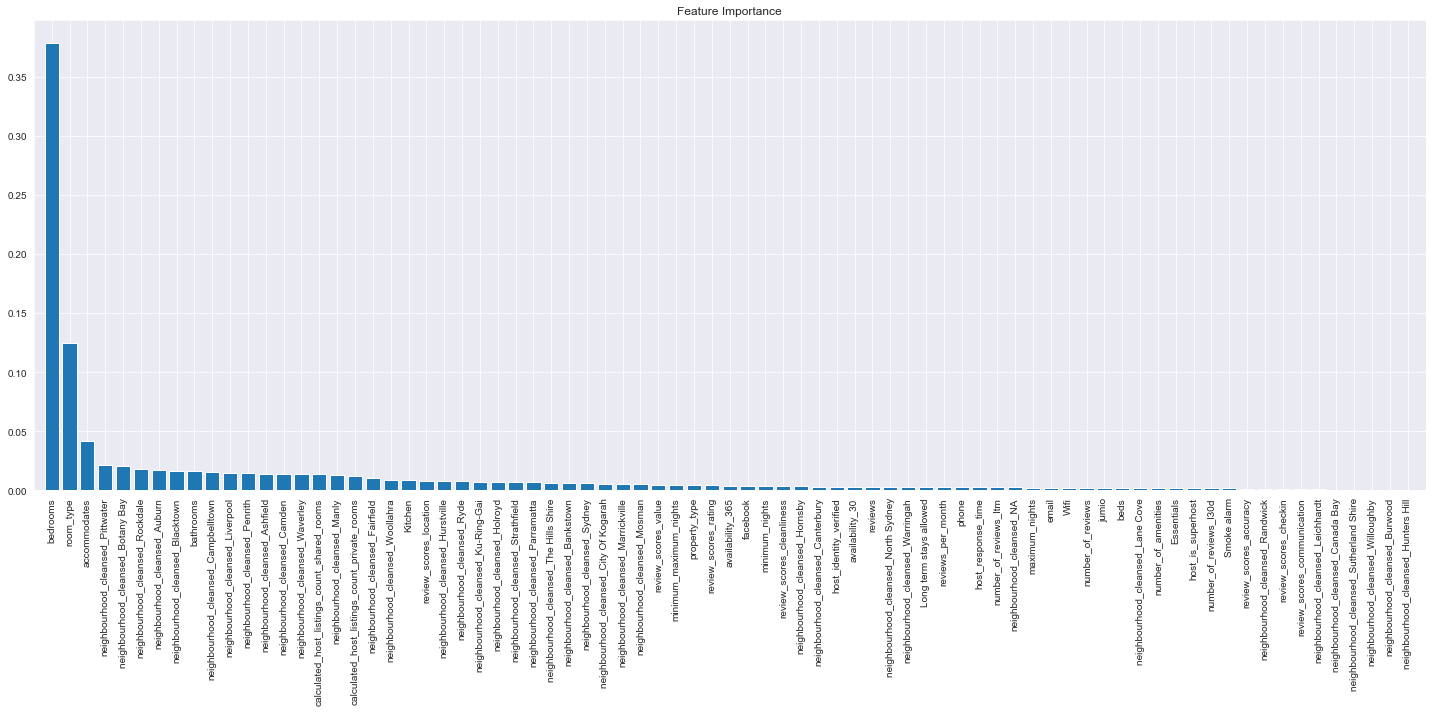

In [320]:
feat_labels = X_train.columns[:]
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.title('Feature Importance')
plt.bar(range(X_train.shape[1]), 
        importances[indices],
        align='center')

plt.xticks(range(X_train.shape[1]), 
           feat_labels[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

#### Visualization comment:
- Similar to the first feature importance visualization, `bedroom` and `room_type` are the most 2 imporant independent variable to predict the target variable (price) according to XGBRegressor.

### Model Comparison:

| **Regression Model** | **RMSE train** | **RMSE test** |
| :- | -: | :- |
| Linear Regression | 0.4421| 0.4406 |
| Lasso Regression | 0.4422 | 0.4406 |
| Ridge Regression| 0.196 | 0.194 |
| Elasticnet | 0.442 | 0.441 |
| DecisionTree Regression | 0.000 | 0.594 |
| Bagging Regression | 0.160 | 0.429 |
| Adaboost Regression | 0.530 | 0.547 |
| Standard Scaler| 0.320 | 0.421 |
| Gradient Boosting Regression | 0.226 | 0.394 | 

- The mean of RMSE is at 0.4, minimum RMSE is 0 and maximum is 0.4422 for the train data.
- Although, the **DecisionTree Regression** return the best RMSE which is 0 in the train data; however, it returns 0.594 RMSE for the test dataset which indicates that the model is overfitting and cannot perform well in the test data.
- The Ridge Regression doesn't have the best RMSE among the regressions. However, this model return the least RMSE that has a stable RMSE value from train dataset compared to the test dataset. Therefore, this model is most likely to perform well with the prediction.

### 4. Predicting outputs and Kaggle Score Rank

In [322]:
clf_elasticnet.fit(x2,y2)
clf_lasso.fit(x2,y2)
clf_ridge.fit(x2,y2)
gbr.fit(x2,y2)

y_blend=pd.DataFrame(np.exp(0.5 * clf_ridge.predict(x2_test)
                           +(0.5 * gbr.predict(x2_test))),columns={'price'})




sub=pd.DataFrame()
sub['ID']=test_id
sub['price']=y_blend
sub.to_csv('submission1.csv', index=False)


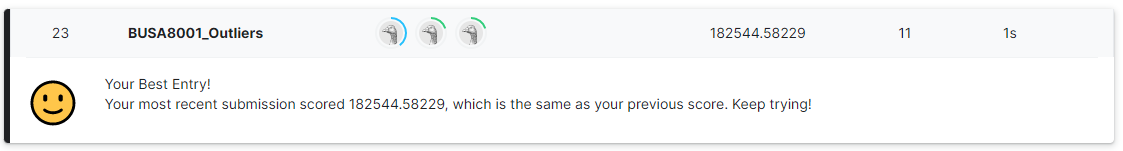

#### Comment:
- Same as intuition, this is the best scores on Kaggle so far which is generated by the Ridge Regression model. 